In [45]:
#Logistic regression with Advertising Dataset
#--------------------------------------------
#------------------------------------------------

#Step 1 : Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as lpt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_curve, auc

# print("Libraries imported")


In [46]:
 # Step 2: Load dataset
data = pd.read_csv("advertising.csv")
print("First 5 rows of dataset:\n",data.head())

First 5 rows of dataset:
    Daily Time Spent on Site  Age  Area Income  Daily Internet Usage  \
0                     68.95   35     61833.90                256.09   
1                     80.23   31     68441.85                193.77   
2                     69.47   26     59785.94                236.50   
3                     74.15   29     54806.18                245.89   
4                     68.37   35     73889.99                225.58   

                           Ad Topic Line            City  Male     Country  \
0     Cloned 5thgeneration orchestration     Wrightburgh     0     Tunisia   
1     Monitored national standardization       West Jodi     1       Nauru   
2       Organic bottom-line service-desk        Davidton     0  San Marino   
3  Triple-buffered reciprocal time-frame  West Terrifurt     1       Italy   
4          Robust logistical utilization    South Manuel     0     Iceland   

          Timestamp  Clicked on Ad  
0  27-03-2016 00:53              0  
1  0

In [47]:
# Step 3: Select Features and Target

# Select input features (independent variables)
X = data[
    [
        'Daily Time Spent on Site',
        'Age',
        'Area Income',
        'Daily Internet Usage',
        'Male'
    ]
]

# Select target variable (dependent variable)
y = data['Clicked on Ad']

# Check the shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())

Features shape: (1000, 5)
Target shape: (1000,)

Features:
   Daily Time Spent on Site  Age  Area Income  Daily Internet Usage  Male
0                     68.95   35     61833.90                256.09     0
1                     80.23   31     68441.85                193.77     1
2                     69.47   26     59785.94                236.50     0
3                     74.15   29     54806.18                245.89     1
4                     68.37   35     73889.99                225.58     0

Target:
0    0
1    0
2    0
3    0
4    0
Name: Clicked on Ad, dtype: int64


In [48]:
# Step 4: Split dataset into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [49]:
# Display the shapes of the training and testing datasets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (700, 5)
X_test shape: (300, 5)
y_train shape: (700,)
y_test shape: (300,)


In [50]:
# Step 5: Scale features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [51]:
# Step 6 : Train Logistic Regression model
model = LogisticRegression()
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [52]:
#Step 7 : Predictions
y_pred = model.predict(X_test)

In [53]:
# Step 8: Evaluate model
print("\nModel Accuracy:",accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n",classification_report(y_test, y_pred))


Model Accuracy: 0.97

Confusion Matrix:
 [[143   3]
 [  6 148]]

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.98      0.97       146
           1       0.98      0.96      0.97       154

    accuracy                           0.97       300
   macro avg       0.97      0.97      0.97       300
weighted avg       0.97      0.97      0.97       300



In [54]:
# Step 9 :ROC Curve & AUC
from sklearn.metrics import roc_curve

y_prob = model.predict_proba(X_test)[:,1] 
fpr, tpr, thersholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

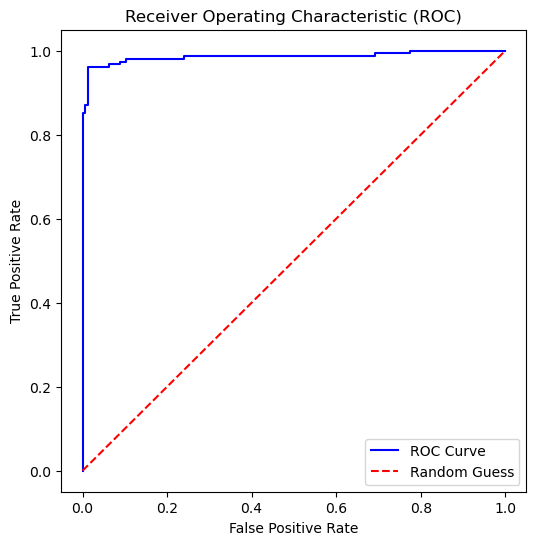

In [55]:
# Step 1: Import Matplotlib
import matplotlib.pyplot as plt

# Step 2: Plot ROC curve
plt.figure(figsize=(6, 6))

plt.plot(fpr, tpr, color='blue', label='ROC Curve')

# Random guess line
plt.plot([0, 1], [0, 1], color='red',
         linestyle='--', label='Random Guess')

# Step 3: Add labels and title
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')

plt.show()